In [1]:
import torch

a = torch.randn(5000, 5000, device="cuda")
b = torch.randn(5000, 5000, device="cuda")

c = torch.matmul(a, b)

print("Device:", c.device)
print("Result shape:", c.shape)

print(
    "GPU Memory Allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Device: cuda:0
Result shape: torch.Size([5000, 5000])
GPU Memory Allocated: 0.29 GB


In [2]:
import sys
import torch
import pandas
import numpy
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
PyTorch: 2.11.0+cu128
CUDA: True
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from pathlib import Path
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

In [4]:
PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SPLIT_DIR = PROJECT_DIR / "data" / "splits"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Raw data:", RAW_DIR)

Project: c:\Users\Kowshik\my-project\text-summarization-system
Raw data: c:\Users\Kowshik\my-project\text-summarization-system\data\raw


In [5]:
bbc_path = RAW_DIR / "bbc-news-summary.csv"
cnn_path = RAW_DIR / "cnn_dailymail_test_dataset.csv"

bbc = pd.read_csv(bbc_path)
cnn = pd.read_csv(cnn_path)

print("BBC Shape:", bbc.shape)
print("CNN Shape:", cnn.shape)

BBC Shape: (2224, 3)
CNN Shape: (11490, 3)


In [6]:
print("BBC Columns:")
print(bbc.columns.tolist())

print("\nCNN Columns:")
print(cnn.columns.tolist())

BBC Columns:
['File_path', 'Articles', 'Summaries']

CNN Columns:
['article', 'highlights', 'id']


In [7]:
print("BBC Information:")
bbc.info()

print("\nCNN Information:")
cnn.info()

BBC Information:
<class 'pandas.DataFrame'>
RangeIndex: 2224 entries, 0 to 2223
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   File_path  2224 non-null   str  
 1   Articles   2224 non-null   str  
 2   Summaries  2224 non-null   str  
dtypes: str(3)
memory usage: 52.3 KB

CNN Information:
<class 'pandas.DataFrame'>
RangeIndex: 11490 entries, 0 to 11489
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   article     11490 non-null  str  
 1   highlights  11490 non-null  str  
 2   id          11490 non-null  str  
dtypes: str(3)
memory usage: 269.4 KB


In [8]:
display(bbc.head(3))
display(cnn.head(3))

,File_path,Articles,Summaries
0,politics,Budget to set scene for election..Gordon Brown will seek to put the economy at the centre of Labour's bid for a third term in power when he delivers his ninth Budget at 1230 GMT. He is expected to...,"- Increase in the stamp duty threshold from £60,000 - A freeze on petrol duty - An extension of tax credit scheme for poorer families - Possible help for pensioners The stamp duty threshold rise i..."
1,politics,"Army chiefs in regiments decision..Military chiefs are expected to meet to make a final decision on the future of Scotland's Army regiments...A committee of the Army Board, which is made up of the...","""They are very much not for the good and will destroy Scotland's regiments by moulding them into a single super regiment which will lead to severe recruitment problems, a loss of local connections..."
2,politics,Howard denies split over ID cards..Michael Howard has denied his shadow cabinet was split over its decision to back controversial Labour plans to introduce ID cards...The Tory leader said his fron...,"Michael Howard has denied his shadow cabinet was split over its decision to back controversial Labour plans to introduce ID cards.Mr Howard said the police had said ID cards could ""help them foil ..."


,article,highlights,id
0,"(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian terr...","Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .\nIsrael and the United States opposed the move, which could open the door to war cr...",f001ec5c4704938247d27a44948eebb37ae98d01
1,"(CNN)Never mind cats having nine lives. A stray pooch in Washington State has used up at least three of her own after being hit by a car, apparently whacked on the head with a hammer in a misguide...","Theia, a bully breed mix, was apparently hit by a car, whacked with a hammer and buried in a field .\n""She's a true miracle dog and she deserves a good life,"" says Sara Mellado, who is looking for...",230c522854991d053fe98a718b1defa077a8efef
2,"(CNN)If you've been following the news lately, there are certain things you doubtless know about Mohammad Javad Zarif. He is, of course, the Iranian foreign minister. He has been U.S. Secretary of...",Mohammad Javad Zarif has spent more time with John Kerry than any other foreign minister .\nHe once participated in a takeover of the Iranian Consulate in San Francisco .\nThe Iranian foreign mini...,4495ba8f3a340d97a9df1476f8a35502bcce1f69


In [9]:
print("BBC ARTICLE:")
print(bbc["Articles"].iloc[0])

print("\nBBC SUMMARY:")
print(bbc["Summaries"].iloc[0])

BBC ARTICLE:
Budget to set scene for election..Gordon Brown will seek to put the economy at the centre of Labour's bid for a third term in power when he delivers his ninth Budget at 1230 GMT. He is expected to stress the importance of continued economic stability, with low unemployment and interest rates. The chancellor is expected to freeze petrol duty and raise the stamp duty threshold from £60,000. But the Conservatives and Lib Dems insist voters face higher taxes and more means-testing under Labour...Treasury officials have said there will not be a pre-election giveaway, but Mr Brown is thought to have about £2bn to spare...- Increase in the stamp duty threshold from £60,000. - A freeze on petrol duty. - An extension of tax credit scheme for poorer families. - Possible help for pensioners The stamp duty threshold rise is intended to help first time buyers - a likely theme of all three of the main parties' general election manifestos. Ten years ago, buyers had a much greater chance 

In [10]:
print("BBC Missing Values:")
display(bbc.isnull().sum())

print("CNN Missing Values:")
display(cnn.isnull().sum())

BBC Missing Values:


File_path    0
Articles     0
Summaries    0
dtype: int64

CNN Missing Values:


article       0
highlights    0
id            0
dtype: int64

In [11]:
print("BBC Duplicate Rows:", bbc.duplicated().sum())
print("CNN Duplicate Rows:", cnn.duplicated().sum())

BBC Duplicate Rows: 98
CNN Duplicate Rows: 0


In [12]:
print(
    "BBC Duplicate Articles:",
    bbc["Articles"].duplicated().sum()
)

print(
    "CNN Duplicate Articles:",
    cnn["article"].duplicated().sum()
)

BBC Duplicate Articles: 98
CNN Duplicate Articles: 2


In [13]:
def clean_text(text):

    if not isinstance(text, str):
        return ""

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [14]:
bbc_clean = bbc[["Articles", "Summaries"]].copy()

bbc_clean.columns = ["article", "summary"]

bbc_clean["article"] = bbc_clean["article"].apply(clean_text)
bbc_clean["summary"] = bbc_clean["summary"].apply(clean_text)

# Remove empty records
bbc_clean = bbc_clean[
    (bbc_clean["article"] != "") &
    (bbc_clean["summary"] != "")
]

# Remove duplicate article-summary pairs
bbc_clean = bbc_clean.drop_duplicates(
    subset=["article", "summary"]
)

# Remove repeated articles
bbc_clean = bbc_clean.drop_duplicates(
    subset=["article"]
)

bbc_clean = bbc_clean.reset_index(drop=True)

print("Original BBC:", len(bbc))
print("Clean BBC:", len(bbc_clean))

Original BBC: 2224
Clean BBC: 2126


In [15]:
cnn_clean = cnn[["article", "highlights"]].copy()

cnn_clean.columns = ["article", "summary"]

cnn_clean["article"] = cnn_clean["article"].apply(clean_text)
cnn_clean["summary"] = cnn_clean["summary"].apply(clean_text)

cnn_clean = cnn_clean[
    (cnn_clean["article"] != "") &
    (cnn_clean["summary"] != "")
]

cnn_clean = cnn_clean.drop_duplicates(
    subset=["article", "summary"]
)

cnn_clean = cnn_clean.drop_duplicates(
    subset=["article"]
)

cnn_clean = cnn_clean.reset_index(drop=True)

print("Original CNN:", len(cnn))
print("Clean CNN:", len(cnn_clean))

Original CNN: 11490
Clean CNN: 11488


In [16]:
for dataset in [bbc_clean, cnn_clean]:

    dataset["article_words"] = (
        dataset["article"].str.split().str.len()
    )

    dataset["summary_words"] = (
        dataset["summary"].str.split().str.len()
    )

In [17]:
print("BBC Article Statistics:")
display(bbc_clean["article_words"].describe())

print("BBC Summary Statistics:")
display(bbc_clean["summary_words"].describe())

BBC Article Statistics:


count    2126.000000
mean      379.332079
std       238.239918
min        87.000000
25%       241.250000
50%       327.000000
75%       465.000000
max      4377.000000
Name: article_words, dtype: float64

BBC Summary Statistics:


count    2126.000000
mean      165.339135
std       110.319038
min        38.000000
25%       103.000000
50%       142.000000
75%       202.000000
max      2073.000000
Name: summary_words, dtype: float64

In [18]:
print("CNN Article Statistics:")
display(cnn_clean["article_words"].describe())

print("CNN Summary Statistics:")
display(cnn_clean["summary_words"].describe())

CNN Article Statistics:


count    11488.000000
mean       683.469795
std        348.276426
min         55.000000
25%        419.000000
50%        613.000000
75%        876.000000
max       1954.000000
Name: article_words, dtype: float64

CNN Summary Statistics:


count    11488.000000
mean        55.013318
std         22.517302
min          9.000000
25%         40.000000
50%         51.000000
75%         64.000000
max        564.000000
Name: summary_words, dtype: float64

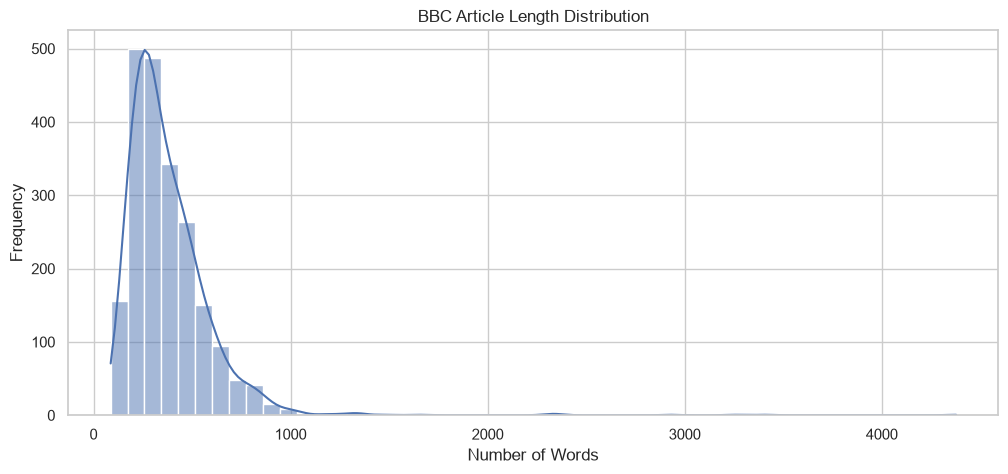

In [19]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=bbc_clean,
    x="article_words",
    bins=50,
    kde=True
)

plt.title("BBC Article Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

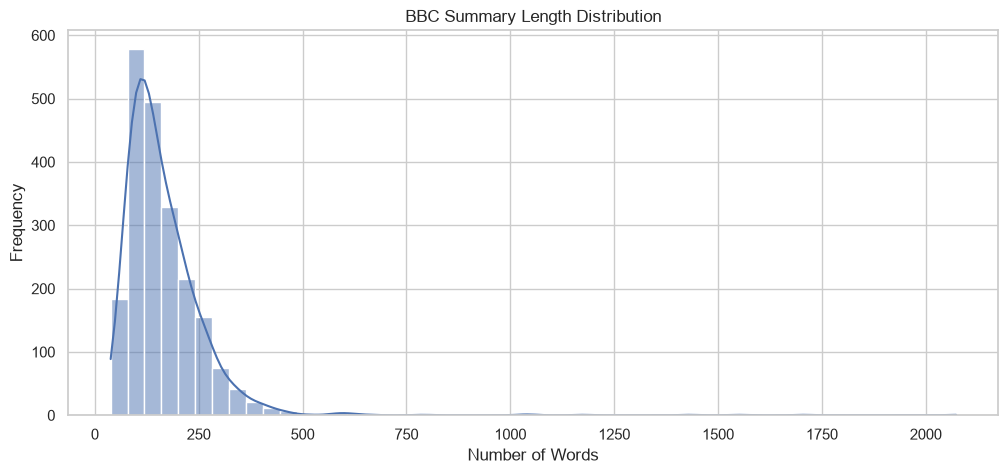

In [20]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=bbc_clean,
    x="summary_words",
    bins=50,
    kde=True
)

plt.title("BBC Summary Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

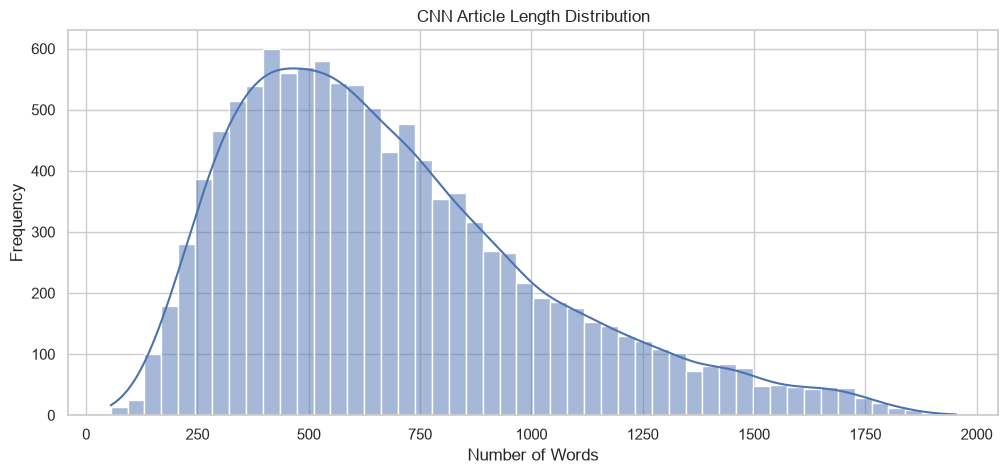

In [21]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=cnn_clean,
    x="article_words",
    bins=50,
    kde=True
)

plt.title("CNN Article Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

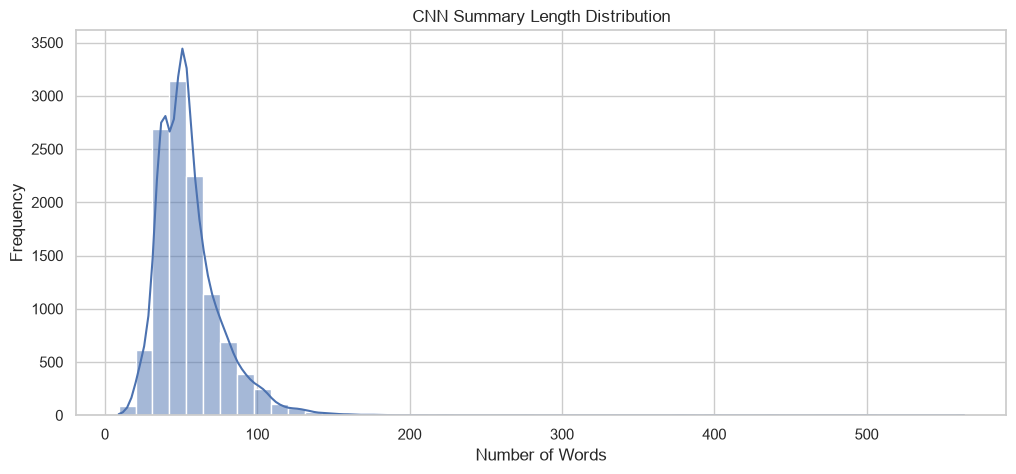

In [22]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=cnn_clean,
    x="summary_words",
    bins=50,
    kde=True
)

plt.title("CNN Summary Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [23]:
def calculate_compression(dataset):

    article_words = dataset["article_words"].sum()
    summary_words = dataset["summary_words"].sum()

    ratio = (summary_words / article_words) * 100

    return round(ratio, 2)


print(
    "BBC Compression Ratio:",
    calculate_compression(bbc_clean),
    "%"
)

print(
    "CNN Compression Ratio:",
    calculate_compression(cnn_clean),
    "%"
)

BBC Compression Ratio: 43.59 %
CNN Compression Ratio: 8.05 %
